# Simulação

Compare Butterworth, Chebyshev I e elíptico para fs = 1000 Hz, fp = 80 Hz, fr = 150 Hz, Ap = 1 dB e Ar = 40 dB.

Execute as células em ordem. Os dados são sintéticos; não representam medições experimentais.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
import pandas as pd
from IPython.display import display
plt.rcParams.update({'figure.figsize': (10, 4), 'axes.grid': True})

def espectro(x, fs, janela=None, nfft=None):
    w = np.ones(len(x)) if janela is None else janela
    X = np.fft.rfft(x*w, n=nfft)
    f = np.fft.rfftfreq(len(x) if nfft is None else nfft, 1/fs)
    A = np.abs(X)/w.sum()
    A[1:] *= 2
    if (len(x) if nfft is None else nfft) % 2 == 0:
        A[-1] /= 2
    return f, A

def plano(b, a, ax):
    # Coeficientes em potências de z^-1; completar graus para exibir polos na origem.
    grau = max(len(b), len(a))-1
    z = np.roots(np.pad(b, (0, grau+1-len(b))))
    p = np.roots(np.pad(a, (0, grau+1-len(a))))
    theta = np.linspace(0, 2*np.pi, 500)
    ax.plot(np.cos(theta), np.sin(theta), 'k--', label='Círculo unitário')
    ax.scatter(z.real, z.imag, facecolors='none', edgecolors='C0', label='Zeros')
    ax.scatter(p.real, p.imag, marker='x', color='C1', label='Polos')
    ax.set(xlabel='Parte real', ylabel='Parte imaginária', title='Plano z')
    ax.axis('equal'); ax.legend()

def analisar(b, a=(1,), fs=1000, nome='Filtro'):
    w, H = signal.freqz(b, a, worN=4096, fs=fs)
    impulso = np.r_[1., np.zeros(119)]
    h = signal.lfilter(b, a, impulso)
    fig, ax = plt.subplots(2, 3, figsize=(14, 7))
    ax[0,0].stem(np.arange(len(h)), h); ax[0,0].set(title=nome+' — impulso', xlabel='n (amostras)', ylabel='h[n]')
    plano(np.asarray(b), np.asarray(a), ax[0,1])
    ax[0,2].plot(w, np.abs(H)); ax[0,2].set(title='Magnitude linear', xlabel='f (Hz)', ylabel='Ganho')
    ax[1,0].plot(w, 20*np.log10(np.maximum(np.abs(H), 1e-12))); ax[1,0].set(title='Magnitude em dB', xlabel='f (Hz)', ylabel='Ganho (dB)', ylim=(-100,5))
    fase = np.unwrap(np.angle(H))
    ax[1,1].plot(w, fase); ax[1,1].set(title='Fase', xlabel='f (Hz)', ylabel='Fase (rad)')
    gd = -np.gradient(fase, 2*np.pi*w/fs)
    gd[np.abs(H)<1e-5] = np.nan
    ax[1,2].plot(w, gd); ax[1,2].set(title='Atraso de grupo (fora dos nulos)', xlabel='f (Hz)', ylabel='Amostras')
    fig.tight_layout(); plt.show()
    print('b =', np.asarray(b)); print('a =', np.asarray(a))
    print('Polos:', np.roots(a), 'Estável causal:', np.all(np.abs(np.roots(a)) < 1))


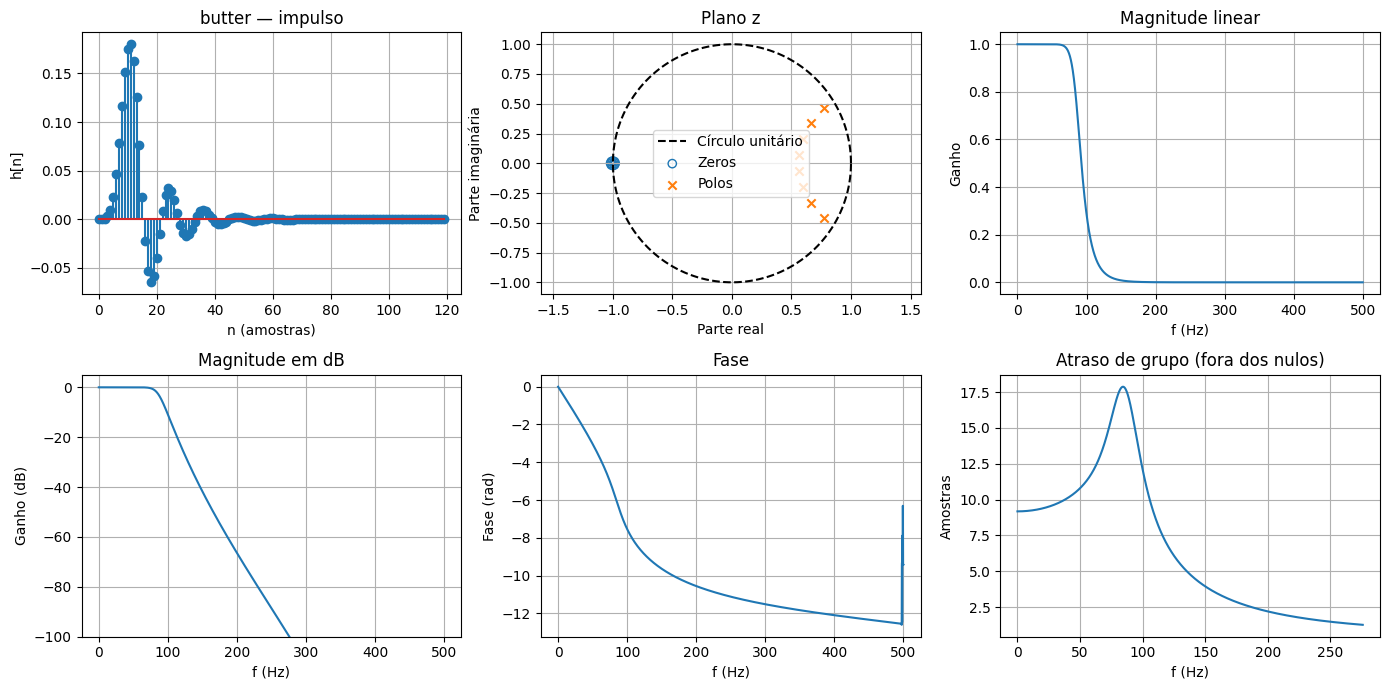

b = [8.97754728e-06 7.18203783e-05 2.51371324e-04 5.02742648e-04
 6.28428310e-04 5.02742648e-04 2.51371324e-04 7.18203783e-05
 8.97754728e-06]
a = [  1.          -5.21053433  12.22219774 -16.76747247  14.66317686
  -8.34855367   3.01616106  -0.63117624   0.05849931]
Polos: [0.77666109+0.46166593j 0.77666109-0.46166593j 0.66399355+0.33460512j
 0.66399355-0.33460512j 0.59763829+0.20123324j 0.59763829-0.20123324j
 0.56697424+0.06703805j 0.56697424-0.06703805j] Estável causal: True
butter ordem: 8


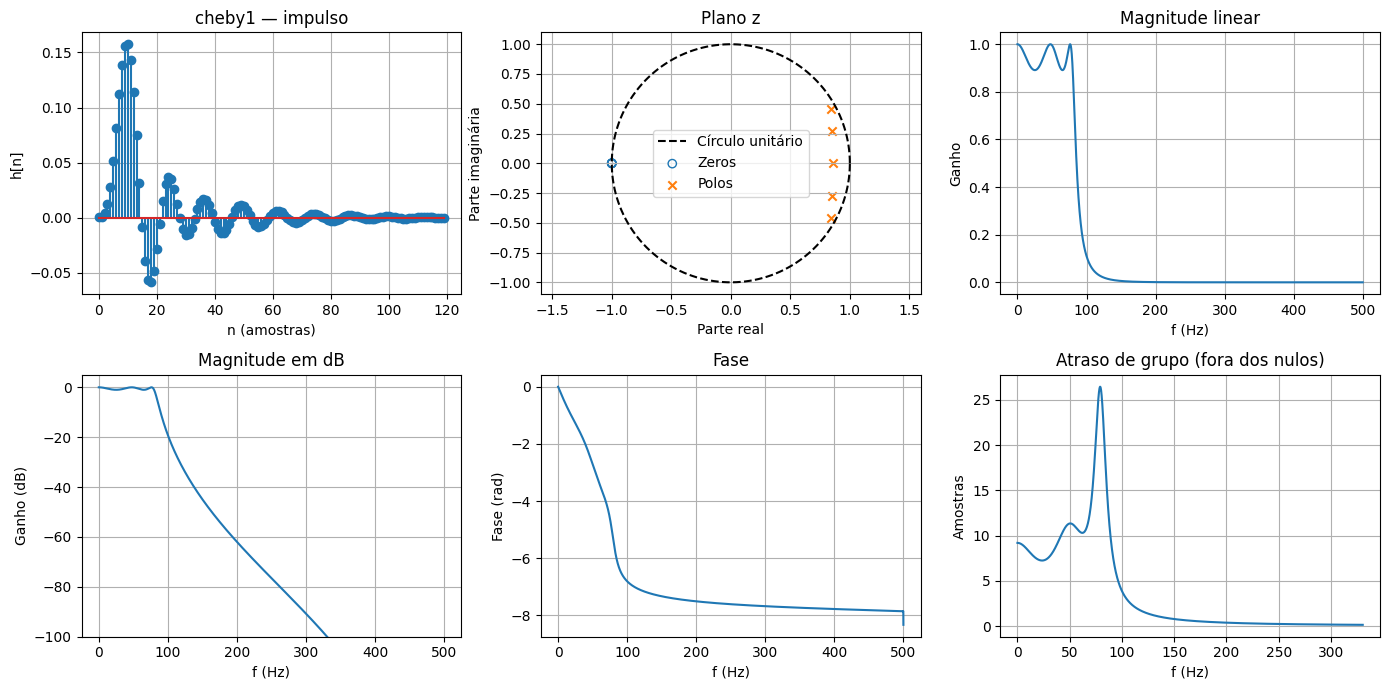

b = [9.99665501e-05 4.99832751e-04 9.99665501e-04 9.99665501e-04
 4.99832751e-04 9.99665501e-05]
a = [ 1.         -4.23639803  7.46293092 -6.80728271  3.20880553 -0.62485679]
Polos: [0.84137669+0.45759741j 0.84137669-0.45759741j 0.84600899+0.2735829j
 0.84600899-0.2735829j  0.86162667+0.j        ] Estável causal: True
cheby1 ordem: 5


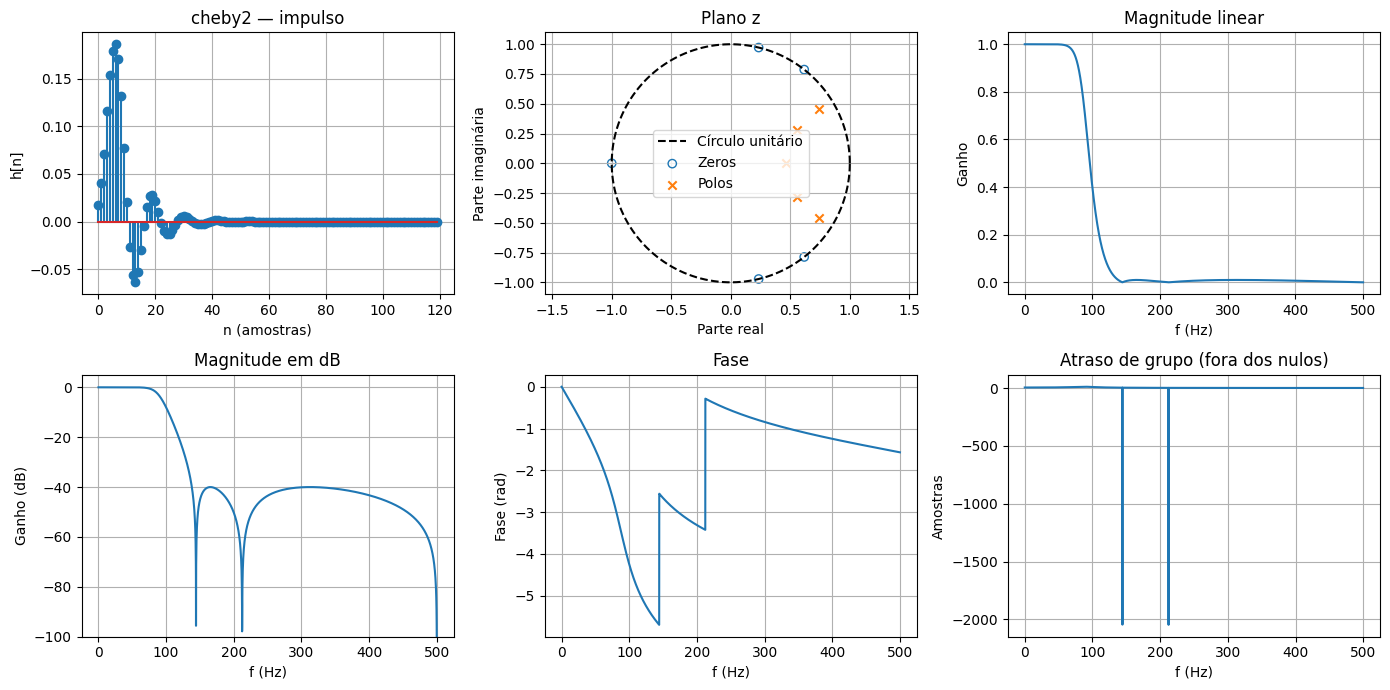

b = [ 0.01732778 -0.01217906  0.01517478  0.01517478 -0.01217906  0.01732778]
a = [ 1.         -3.0701349   4.03014223 -2.74781976  0.96773393 -0.1392745 ]
Polos: [0.74407367+0.45995666j 0.74407367-0.45995666j 0.55820066+0.28166796j
 0.55820066-0.28166796j 0.46558623+0.j        ] Estável causal: True
cheby2 ordem: 5


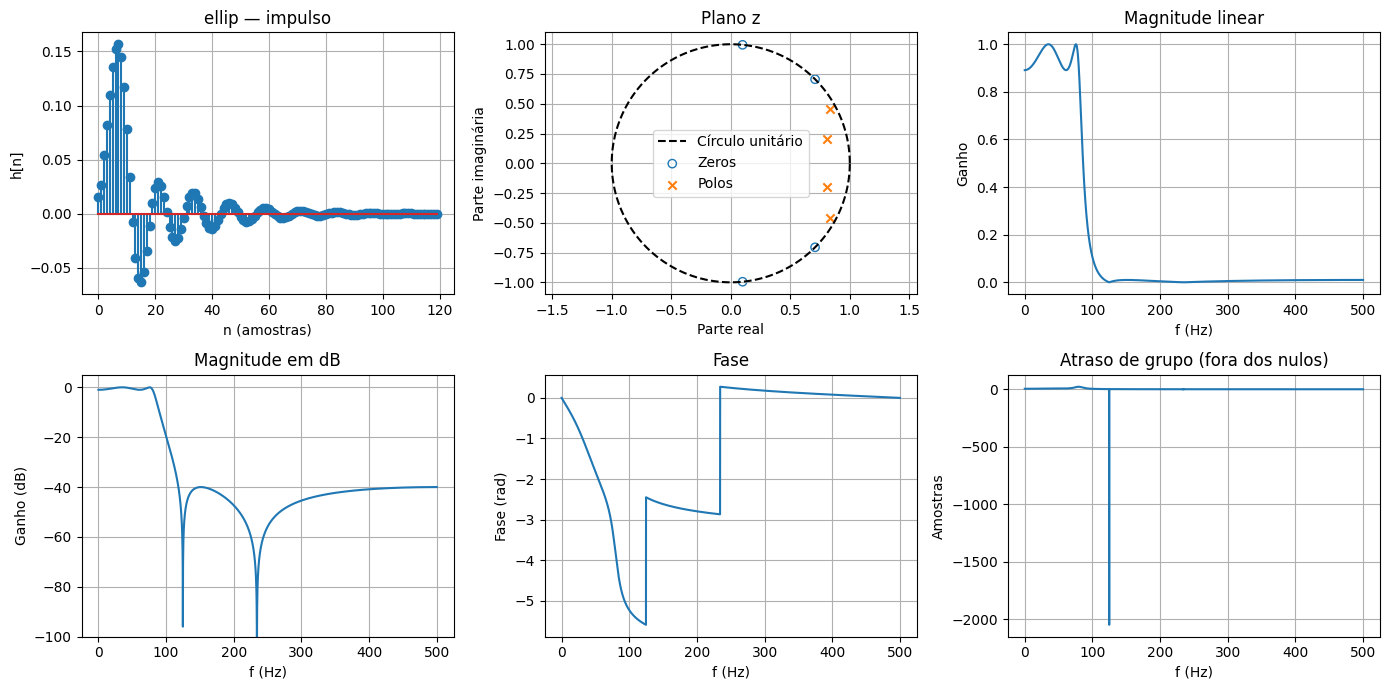

b = [ 0.01570675 -0.02536928  0.03583375 -0.02536928  0.01570675]
a = [ 1.         -3.28057711  4.28424057 -2.60945179  0.62431139]
Polos: [0.83416324+0.45565421j 0.83416324-0.45565421j 0.80612532+0.20296074j
 0.80612532-0.20296074j] Estável causal: True
ellip ordem: 4


In [2]:
for familia in ['butter','cheby1','cheby2','ellip']:
    b,a=signal.iirdesign(80,150,1,40,fs=1000,ftype=familia)
    analisar(b,a,1000,familia)
    print(familia,'ordem:',len(a)-1)